# Tutorial Básico de Scikit-learn

Scikit-learn es la librería estándar de *machine learning* clásico en Python. Está construida sobre NumPy, se integra directamente con Pandas y Matplotlib, y reúne bajo una misma interfaz modelos de regresión, clasificación, agrupamiento y reducción de dimensionalidad, junto con herramientas de preprocesamiento y evaluación. Este tutorial los puede ayudar a comprender los conceptos básicos detrás de esta herramienta, pero queda en sus manos explorar y estudiar los modelos y técnicas que les puedan ser útiles para el curso y para su desarrollo como profesionales. El lugar ideal para hacerlo es la documentación oficial.
- [Documentación de Scikit-learn](https://scikit-learn.org/stable/)
- [Guía de usuario](https://scikit-learn.org/stable/user_guide.html): explica cada modelo con su teoría.
- [Galería de ejemplos](https://scikit-learn.org/stable/auto_examples/index.html): código listo para copiar y adaptar.

Los *llms*, como ChatGPT, Gemini o Claude, pueden ser herramientas muy útiles para estudiarla, resolver problemas y aprender nuevas técnicas. Siempre y cuando se utilicen de manera responsable.

Existen otras librerías que también pueden ser útiles en el contexto de la estadística y el *machine learning*. Aquí algunas de ellas.
- [XGBoost](https://xgboost.readthedocs.io/) y [LightGBM](https://lightgbm.readthedocs.io/): Implementaciones muy eficientes de *gradient boosting*. Suelen ser de los mejores modelos para datos tabulares y son compatibles con la API de Scikit-learn.
- [PyTorch](https://pytorch.org/): Librería de *deep learning* (redes neuronales), para cuando los modelos clásicos no son suficientes.
- [TensorFlow](https://www.tensorflow.org/): Otra librería de *deep learning*, con un ecosistema más amplio que PyTorch, pero con una curva de aprendizaje más pronunciada.
- [Keras](https://keras.io/): Librería de *deep learning* de alto nivel, que funciona sobre TensorFlow y facilita la construcción de redes neuronales.
- [Jax](https://jax.readthedocs.io/en/latest/): Librería de *deep learning* y diferenciación automática, que permite acelerar el entrenamiento de modelos y realizar cálculos en GPU/TPU

---
## 1. La API de Scikit-learn

Todo modelo en Scikit-learn es un objeto que se configura al crearlo y que aprende de los datos con `.fit()`. El patrón es siempre el mismo:

1. Importar la clase del modelo.
2. Crear el objeto, eligiendo sus **hiperparámetros**.
3. Entrenarlo con `.fit(X, y)`.
4. Predecir con `.predict(X_nuevo)`.

La convención es que `X` es una matriz 2D (filas = observaciones, columnas = variables) e `y` es un vector 1D con lo que queremos predecir. Lo que el modelo aprende queda guardado en atributos que terminan en guion bajo, como `coef_`.

In [1]:
# importar la librería
import numpy as np
from sklearn.linear_model import LinearRegression

# horas de estudio (X) y nota obtenida (y)
X = np.array([[1], [2], [3], [4], [5], [6]])   # 2D: 6 observaciones, 1 variable
y = np.array([2.5, 3.1, 3.9, 4.6, 5.0, 5.8])   # 1D: una nota por observación

modelo = LinearRegression()   # 1 y 2: importar y crear
modelo.fit(X, y)              # 3: entrenar

print("Pendiente aprendida:", modelo.coef_.round(3))
print("Intercepto aprendido:", modelo.intercept_.round(3))
print("Predicción para 7 y 8 horas:", modelo.predict([[7], [8]]).round(2))   # 4: predecir

Pendiente aprendida: [0.654]
Intercepto aprendido: 1.86
Predicción para 7 y 8 horas: [6.44 7.09]


### 1.1 Datasets incluidos

Scikit-learn trae varios datasets pequeños para practicar. Con `as_frame=True` los obtenemos directamente como `DataFrame` de Pandas.
Usaremos **Wine**: 178 vinos, 13 mediciones químicas de cada uno y 3 cultivares (la clase a predecir).

In [2]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X = wine.data      # DataFrame con las 13 variables
y = wine.target    # Series con la clase codificada como 0, 1, 2

print("Forma de X:", X.shape)
print("Clases:", wine.target_names.tolist())
print("\nCuántos vinos hay de cada clase:")
print(y.value_counts().sort_index())
X.head(3)

Forma de X: (178, 13)
Clases: ['class_0', 'class_1', 'class_2']

Cuántos vinos hay de cada clase:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0


### 1.2 Separar en entrenamiento y prueba

`train_test_split` separa los datos al azar. `random_state` fija esa aleatoriedad para que el resultado sea reproducible
y `stratify=y` mantiene la proporción de cada clase en ambos conjuntos.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción de clases en train:", y_train.value_counts(normalize=True).sort_index().round(2).to_dict())
print("Proporción de clases en test: ", y_test.value_counts(normalize=True).sort_index().round(2).to_dict())

Entrenamiento: (133, 13) | Prueba: (45, 13)
Proporción de clases en train: {0: 0.33, 1: 0.4, 2: 0.27}
Proporción de clases en test:  {0: 0.33, 1: 0.4, 2: 0.27}


---
## 2. Clasificación

Partamos con k vecinos más cercanos (KNN): para clasificar un vino,
busca los `k` vinos de entrenamiento más parecidos y le asigna la clase mayoritaria entre ellos.
Además de `.predict()`, los clasificadores tienen `.predict_proba()`, que entrega la probabilidad de cada clase.

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Primeras 10 predicciones:", y_pred[:10])
print("Primeros 10 valores reales:", y_test.values[:10])
print("\nProbabilidades para el primer vino:", knn.predict_proba(X_test.iloc[[0]]).round(2))
print("Accuracy (proporción de aciertos):", round(accuracy_score(y_test, y_pred), 3))

Primeras 10 predicciones: [0 1 0 0 1 0 0 1 2 2]
Primeros 10 valores reales: [0 1 0 0 1 0 0 1 1 2]

Probabilidades para el primer vino: [[0.4 0.4 0.2]]
Accuracy (proporción de aciertos): 0.778


### 2.1 Más allá del accuracy

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.75      0.67      0.71        18
     class_2       0.57      0.67      0.62        12

    accuracy                           0.78        45
   macro avg       0.77      0.78      0.77        45
weighted avg       0.79      0.78      0.78        45



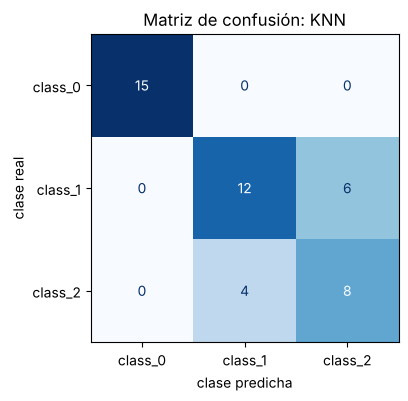

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, y_pred, target_names=wine.target_names))

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=wine.target_names,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matriz de confusión: KNN")
ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real")
plt.show()

### 2.2 Comparar modelos

Como todos los estimadores comparten la misma API, cambiar de modelo es cambiar **una línea**, y podemos recorrer varios en un ciclo.
El método `.score()` de un clasificador devuelve directamente el accuracy.
Comparar el desempeño en *train* y en *test* nos dice si el modelo está sobreajustando (memorizando).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5),
    "Regresión logística": LogisticRegression(max_iter=10_000),
    "Árbol de decisión":   DecisionTreeClassifier(random_state=42),
    "Random forest":       RandomForestClassifier(n_estimators=200, random_state=42),
}

for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    print(f"{nombre:20s} train: {m.score(X_train, y_train):.3f} | test: {m.score(X_test, y_test):.3f}")

KNN (k=5)            train: 0.789 | test: 0.778


Regresión logística  train: 0.992 | test: 0.956
Árbol de decisión    train: 1.000 | test: 0.956


Random forest        train: 1.000 | test: 1.000


---
## 3. Preprocesamiento

KNN quedó bastante peor que el resto. La razón está en las escalas: KNN mide distancias, y la variable `proline`
va de cientos a más de mil, mientras que otras no pasan de 1. En la práctica, KNN solo está mirando `proline`.

`StandardScaler` resta la media y divide por la desviación estándar de cada columna. Los transformadores usan `.fit()`
para aprender (aquí la media y la desviación) y `.transform()` para aplicarlo.

**Importante:** el `.fit()` se hace **solo con train**. Si usamos los datos de prueba para calcular la media,
se filtra información del test al modelo (*data leakage*) y la evaluación deja de ser honesta.

In [7]:
from sklearn.preprocessing import StandardScaler

print("Rango de cada variable (antes):")
print((X_train.max() - X_train.min()).round(2).sort_values().tail(3))

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)   # aprende media/desv. de train y transforma
X_test_esc = scaler.transform(X_test)         # solo transforma, con lo aprendido en train

print("\nMedias después de escalar (train):", X_train_esc.mean(axis=0).round(2)[:4], "...")
print("Desv. después de escalar (train):", X_train_esc.std(axis=0).round(2)[:4], "...")

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_esc, y_train)
print("\nAccuracy de KNN con datos escalados:", round(knn.score(X_test_esc, y_test), 3))

Rango de cada variable (antes):
alcalinity_of_ash      19.4
magnesium              92.0
proline              1237.0
dtype: float64

Medias después de escalar (train): [0. 0. 0. 0.] ...
Desv. después de escalar (train): [1. 1. 1. 1.] ...

Accuracy de KNN con datos escalados: 0.933


### 3.1 Datos faltantes y variables categóricas

Los modelos de Scikit-learn solo aceptan números y, en general, no aceptan `NaN`. Dos transformadores resuelven los casos más comunes:

- **`SimpleImputer`**: rellena faltantes (con la media, la mediana o el valor más frecuente).
- **`OneHotEncoder`**: convierte una columna de texto en una columna 0/1 por cada categoría.

Usemos la tabla de notas del tutorial anterior. Para aplicar transformaciones distintas a columnas distintas existe
[`ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

df = pd.DataFrame({
    "carrera":  ["Ing.", "Ing.", "Ciencias", "Ciencias", "Ing.", "Ciencias", "Ing.", "Ciencias"],
    "prueba_1": [4.5, 6.0, 3.2, 7.0, 5.5, 6.8, 4.0, 5.9],
    "prueba_2": [5.0, 5.5, 4.1, 6.5, 6.0, 6.2, 4.8, np.nan],
})

imputer = SimpleImputer(strategy="mean")
notas = imputer.fit_transform(df[["prueba_1", "prueba_2"]])
print("Media usada para rellenar:", imputer.statistics_.round(2))
print("Última fila ya sin NaN:", notas[-1].round(2))

encoder = OneHotEncoder(sparse_output=False)
carrera = encoder.fit_transform(df[["carrera"]])
print("\nCategorías:", encoder.categories_[0])
print("Codificación one-hot (primeras 4 filas):\n", carrera[:4])

Media usada para rellenar: [5.36 5.44]
Última fila ya sin NaN: [5.9  5.44]

Categorías: ['Ciencias' 'Ing.']
Codificación one-hot (primeras 4 filas):
 [[0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


---
## 4. Pipelines y validación cruzada

Llevar el escalador y el modelo por separado es engorroso y es fácil equivocarse (por ejemplo, olvidar escalar el test).
Un **`Pipeline`** encadena pasos de preprocesamiento y un modelo final en un solo objeto, que se usa igual que cualquier
estimador: `.fit()` aplica `fit_transform` en cada paso y `.predict()` aplica `transform` en cada paso.

In [9]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("escalar", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

pipe.fit(X_train, y_train)     # escala y entrena, todo con train
print("Accuracy del pipeline:", round(pipe.score(X_test, y_test), 3))
pipe

Accuracy del pipeline: 0.933


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalar', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 4.1 Validación cruzada

Con un solo *split*, el resultado depende de qué datos cayeron en el test por azar.
La **validación cruzada** con `k` *folds* divide los datos en `k` partes, entrena `k` veces dejando una parte distinta
para evaluar, y reporta el promedio. Es una estimación mucho más estable del desempeño.

In [10]:
from sklearn.model_selection import cross_val_score

puntajes = cross_val_score(pipe, X_train, y_train, cv=5)   # el pipeline se re-entrena en cada fold

print("Accuracy en cada fold:", puntajes.round(3))
print(f"Promedio: {puntajes.mean():.3f} ± {puntajes.std():.3f}")

Accuracy en cada fold: [1.    0.889 0.963 0.962 0.962]
Promedio: 0.955 ± 0.036


### 4.2 Buscar hiperparámetros: `GridSearchCV`

¿Cuántos vecinos usar? En vez de probar a mano, `GridSearchCV` prueba todas las combinaciones de una grilla, evalúa cada una
con validación cruzada y se queda con la mejor. Los hiperparámetros de un paso del pipeline se nombran `paso__parametro`.
El test se usa **una sola vez**, al final, para reportar el desempeño del modelo elegido.

In [11]:
from sklearn.model_selection import GridSearchCV

grilla = {
    "knn__n_neighbors": [1, 3, 5, 7, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
}

busqueda = GridSearchCV(pipe, grilla, cv=5)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("Accuracy promedio en CV:", round(busqueda.best_score_, 3))
print("Accuracy en test:", round(busqueda.score(X_test, y_test), 3))

resultados = pd.DataFrame(busqueda.cv_results_)
resultados[["param_knn__n_neighbors", "param_knn__weights", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(5)

Mejores hiperparámetros: {'knn__n_neighbors': 15, 'knn__weights': 'uniform'}
Accuracy promedio en CV: 0.977
Accuracy en test: 1.0


,param_knn__n_neighbors,param_knn__weights,mean_test_score
12,21,uniform,0.977208
13,21,distance,0.977208
10,15,uniform,0.977208
11,15,distance,0.977208
8,11,uniform,0.969801


---
## 5. Regresión

La API es exactamente la misma; lo que cambia son los modelos y las métricas.
Usaremos el dataset **Diabetes**: 442 pacientes, 10 variables (edad, IMC, presión, etc.) y como objetivo una medida de la progresión
de la enfermedad un año después.

| Métrica | Interpretación |
|---|---|
| MAE | Error absoluto medio, en las unidades de `y` |
| RMSE | Raíz del error cuadrático medio, castiga más los errores grandes |
| R² | Proporción de la varianza de `y` explicada (1 es perfecto, 0 es igual a predecir la media) |

In [12]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diab = load_diabetes(as_frame=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    diab.data, diab.target, test_size=0.25, random_state=42
)

regresores = {
    "Regresión lineal": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42),
}

for nombre, m in regresores.items():
    m.fit(Xd_train, yd_train)
    pred = m.predict(Xd_test)
    rmse = np.sqrt(mean_squared_error(yd_test, pred))
    print(f"{nombre:17s} MAE: {mean_absolute_error(yd_test, pred):5.1f} | "
          f"RMSE: {rmse:5.1f} | R²: {r2_score(yd_test, pred):.3f}")

Regresión lineal  MAE:  41.5 | RMSE:  53.4 | R²: 0.485


Random forest     MAE:  42.1 | RMSE:  53.2 | R²: 0.488


### 5.1 Visualizar las predicciones

Un buen gráfico para regresión es **real vs. predicho**: si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal.
Los coeficientes de la regresión lineal nos dicen además cuánto pesa cada variable.
Noten también que el random forest no le ganó a la regresión lineal: un modelo más complejo no siempre es mejor.

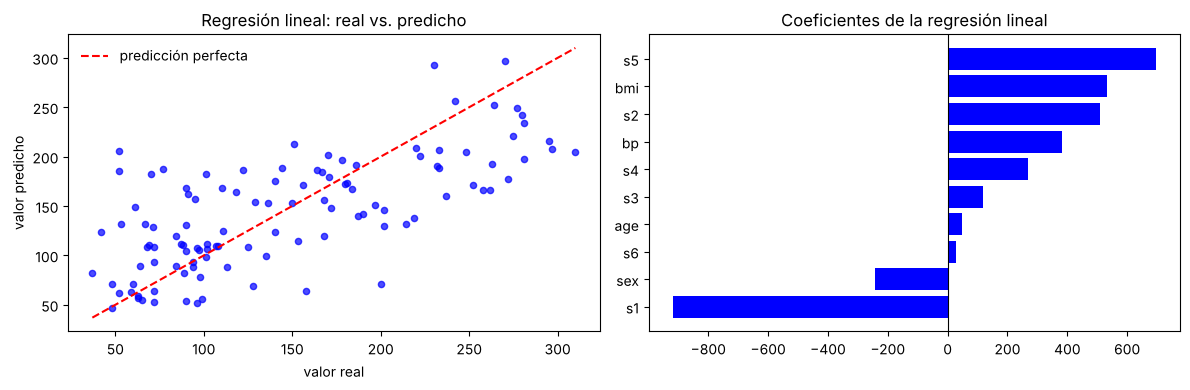

In [13]:
lineal = regresores["Regresión lineal"]
pred = lineal.predict(Xd_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Real vs. predicho
axes[0].scatter(yd_test, pred, s=20, alpha=0.7, color="blue")
lim = [yd_test.min(), yd_test.max()]
axes[0].plot(lim, lim, color="red", linestyle="--", label="predicción perfecta")
axes[0].set_xlabel("valor real"); axes[0].set_ylabel("valor predicho")
axes[0].set_title("Regresión lineal: real vs. predicho"); axes[0].legend(frameon=False)

# Coeficientes
coefs = pd.Series(lineal.coef_, index=diab.feature_names).sort_values()
axes[1].barh(coefs.index, coefs.values, color="blue")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Coeficientes de la regresión lineal")

fig.tight_layout()
plt.show()

---
## 6. Aprendizaje no supervisado

A veces no tenemos `y`: solo queremos encontrar estructura en `X`. Por eso aquí `.fit()` recibe **solo** `X`.

- **PCA** (análisis de componentes principales) reduce las 13 variables a 2 que conservan la mayor varianza posible, lo que nos permite graficar.
- **KMeans** agrupa los datos en `k` *clusters* según su cercanía.

Como no usamos las etiquetas, una buena prueba es comparar los grupos que encuentra KMeans con las clases reales.
Ojo: el número (y el color) que KMeans le asigna a cada grupo es arbitrario; lo que importa es si junta a los mismos vinos.

Varianza explicada por cada componente: [0.362 0.192]


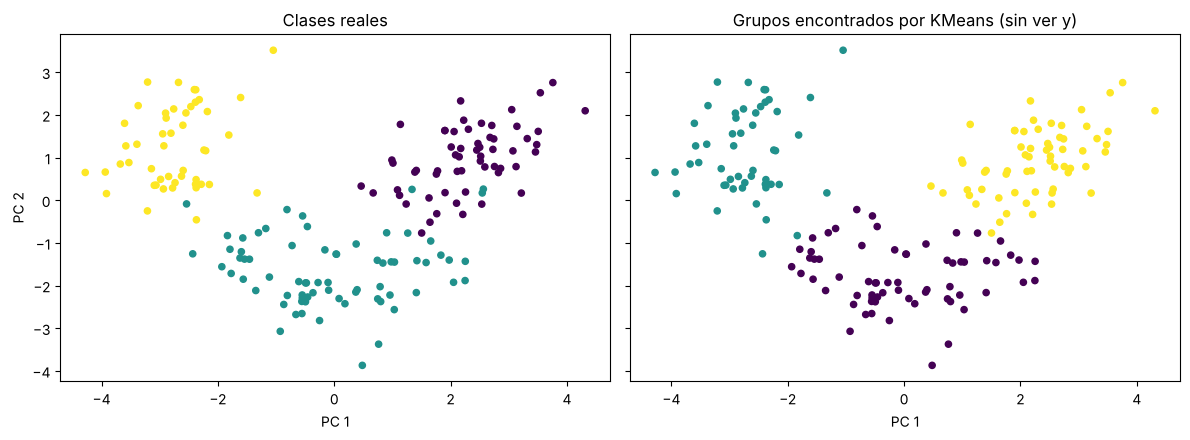

Tabla cruzada clase real vs. grupo:
grupo        0   1   2
clase real            
0            0   0  59
1           65   3   3
2            0  48   0


In [14]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

X_esc = StandardScaler().fit_transform(X)   # escalar es igual de importante aquí

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_esc)
print("Varianza explicada por cada componente:", pca.explained_variance_ratio_.round(3))

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
grupos = kmeans.fit_predict(X_esc)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="viridis", s=20)
axes[0].set_title("Clases reales")
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=grupos, cmap="viridis", s=20)
axes[1].set_title("Grupos encontrados por KMeans (sin ver y)")
for ax in axes:
    ax.set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
fig.tight_layout()
plt.show()

print("Tabla cruzada clase real vs. grupo:")
print(pd.crosstab(y, grupos, rownames=["clase real"], colnames=["grupo"]))

---
## 7. Redes neuronales

Scikit-learn incluye el **perceptrón multicapa** (MLP), la red neuronal más clásica: capas de neuronas donde cada una
está conectada con todas las de la capa siguiente. Cada neurona calcula una combinación lineal de sus entradas y le
aplica una función de activación no lineal; apilar capas es lo que permite aprender relaciones complejas.
Hay dos versiones, `MLPClassifier` y `MLPRegressor`, y se usan con la misma API de siempre.

| Hiperparámetro | Qué controla |
|---|---|
| `hidden_layer_sizes` | La arquitectura: `(32, 16)` son 2 capas ocultas de 32 y 16 neuronas |
| `activation` | Función de activación (`"relu"` por defecto, también `"tanh"`, `"logistic"`) |
| `alpha` | Regularización: valores más altos reducen el sobreajuste |
| `max_iter` | Máximo de épocas (pasadas completas por los datos) de entrenamiento |

Las redes neuronales son **muy sensibles a la escala** de los datos, así que siempre van dentro de un `Pipeline` con `StandardScaler`.

Accuracy  train: 1.000 | test: 0.956
Épocas de entrenamiento: 294
Forma de las matrices de pesos: [(13, 32), (32, 16), (16, 3)]


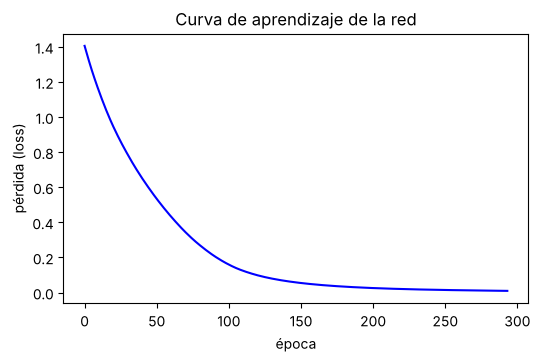

In [15]:
from sklearn.neural_network import MLPClassifier

red = Pipeline([
    ("escalar", StandardScaler()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=1000, random_state=42)),
])
red.fit(X_train, y_train)

print(f"Accuracy  train: {red.score(X_train, y_train):.3f} | test: {red.score(X_test, y_test):.3f}")

mlp = red.named_steps["mlp"]        # acceder a un paso del pipeline
print("Épocas de entrenamiento:", mlp.n_iter_)
print("Forma de las matrices de pesos:", [w.shape for w in mlp.coefs_])   # 13 → 32 → 16 → 3

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(mlp.loss_curve_, color="blue")
ax.set_title("Curva de aprendizaje de la red")
ax.set_xlabel("época"); ax.set_ylabel("pérdida (loss)")
plt.show()

### 7.1 Regresión con redes y sus límites

`MLPRegressor` funciona igual. Con `early_stopping=True` la red separa internamente un 10% de los datos de entrenamiento
y deja de entrenar cuando el error en esa parte deja de mejorar, lo que ayuda a no sobreajustar.

En datasets chicos y tabulares como estos, una red neuronal rara vez le gana a modelos más simples, y es más lenta y difícil de ajustar.
Además, Scikit-learn no usa GPU ni permite arquitecturas especiales (convolucionales, recurrentes, *transformers*).
Para imágenes, texto o grandes volúmenes de datos conviene pasar a [PyTorch](https://pytorch.org/).

In [16]:
from sklearn.neural_network import MLPRegressor

red_reg = Pipeline([
    ("escalar", StandardScaler()),
    ("mlp", MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1.0, learning_rate_init=0.01,
                         early_stopping=True, max_iter=2000, random_state=42)),
])
red_reg.fit(Xd_train, yd_train)
pred_red = red_reg.predict(Xd_test)

print(f"Red neuronal      R²: {r2_score(yd_test, pred_red):.3f} "
      f"(épocas: {red_reg.named_steps['mlp'].n_iter_})")
print(f"Regresión lineal  R²: {r2_score(yd_test, lineal.predict(Xd_test)):.3f}")

Red neuronal      R²: 0.434 (épocas: 68)
Regresión lineal  R²: 0.485


---
## Resumen

| Qué quiero | Cómo |
|---|---|
| Entrenar un modelo | `modelo.fit(X_train, y_train)` |
| Predecir | `modelo.predict(X_nuevo)` / `modelo.predict_proba(X_nuevo)` |
| Evaluar rápido | `modelo.score(X_test, y_test)` |
| Separar train/test | `train_test_split(X, y, test_size=..., random_state=...)` |
| Preprocesar | `StandardScaler`, `SimpleImputer`, `OneHotEncoder` (`fit` solo con train) |
| Encadenar pasos | `Pipeline([("paso", transformador), ..., ("modelo", estimador)])` |
| Evaluar con más estabilidad | `cross_val_score(modelo, X, y, cv=5)` |
| Elegir hiperparámetros | `GridSearchCV(modelo, grilla, cv=5)` |
| Métricas de clasificación | `accuracy_score`, `classification_report`, `ConfusionMatrixDisplay` |
| Métricas de regresión | `mean_absolute_error`, `mean_squared_error`, `r2_score` |
| Sin etiquetas | `PCA`, `KMeans` (`fit` solo con `X`) |
| Redes neuronales | `MLPClassifier`, `MLPRegressor` (siempre con `StandardScaler`) |